C:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - accuracy: 0.9496 - loss: 0.1738
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 24s 16ms/step - accuracy: 0.9836 - loss: 0.0555
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9889 - loss: 0.0364
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9925 - loss: 0.0241
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - accuracy: 0.9948 - loss: 0.0173
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9864 - loss: 0.0438 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
MODEL 1 RESULTS
Accuracy: 98.64000082015991
Loss: 0.043800726532936096


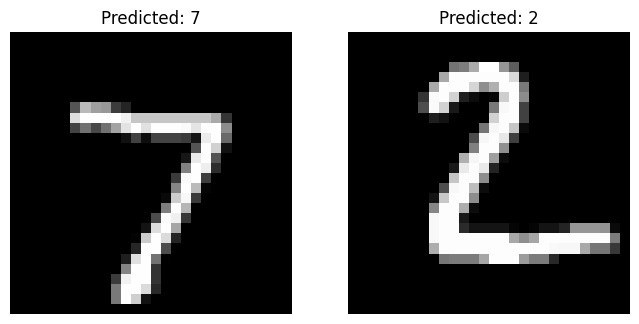

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 18s 17ms/step - accuracy: 0.9508 - loss: 0.1608
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 16s 17ms/step - accuracy: 0.9849 - loss: 0.0478
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - accuracy: 0.9900 - loss: 0.0327
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.9923 - loss: 0.0244
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.9944 - loss: 0.0186
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9871 - loss: 0.0384 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
MODEL 2 RESULTS
Accuracy: 98.71000051498413
Loss: 0.03843217343091965


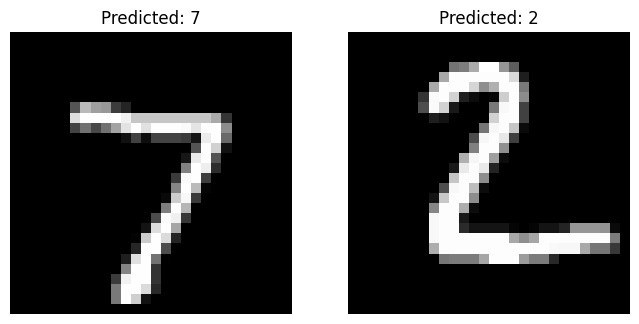

In [1]:

import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical

# Load dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalize images
x_train = x_train.reshape(-1,28,28,1) / 255.0
x_test = x_test.reshape(-1,28,28,1) / 255.0

# One hot encoding
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)


# MODEL 1 - One convolution layer
model1 = Sequential([
    Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128,activation='relu'),
    Dense(10,activation='softmax')
])

# Compile and train Model 1
model1.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])
model1.fit(x_train,y_train,epochs=5,batch_size=64)

# Evaluate Model 1
loss1, acc1 = model1.evaluate(x_test,y_test)
pred1 = model1.predict(x_test[:2])

print("MODEL 1 RESULTS")
print("Accuracy:",acc1*100)
print("Loss:",loss1)

# Figure 1 - Model 1 predictions
plt.figure(figsize=(8,4))

for i in range(2):
    plt.subplot(1,2,i+1)
    plt.imshow(x_test[i],cmap='gray')
    plt.title("Predicted: " + str(pred1[i].argmax()))
    plt.axis('off')

plt.show()


# MODEL 2 - Two convolution layers
model2 = Sequential([
    Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)),
    MaxPooling2D((2,2)),
    Conv2D(64,(3,3),activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128,activation='relu'),
    Dense(10,activation='softmax')
])

# Compile and train Model 2
model2.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])
model2.fit(x_train,y_train,epochs=5,batch_size=64)

# Evaluate Model 2
loss2, acc2 = model2.evaluate(x_test,y_test)
pred2 = model2.predict(x_test[:2])

print("MODEL 2 RESULTS")
print("Accuracy:",acc2*100)
print("Loss:",loss2)

# Figure 2 - Model 2 predictions
plt.figure(figsize=(8,4))

for i in range(2):
    plt.subplot(1,2,i+1)
    plt.imshow(x_test[i],cmap='gray')
    plt.title("Predicted: " + str(pred2[i].argmax()))
    plt.axis('off')

plt.show()